<a href="https://colab.research.google.com/github/princeomarmohamed55/AI-PORTFOLIO-2026/blob/main/AI_ASSIGNMENT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Healthcare Stroke Prediction Model

1. Project Goals & Objectives
Problem: Identify patients at high risk of stroke using routine demographic and health metrics.
Objective: Train a reliable Logistic Regression classifier that predicts the `stroke` target variable (1 = stroke, 0 = no stroke).
Success Criteria: Because approximately 5% of patients experience a stroke, standard accuracy is misleading. Core targets: recall (stroke class) ≥ 0.75 and ROC-AUC ≥ 0.80, balancing precision adequately.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder

pd.set_option('display.max_columns', None)
#write a note
from google.colab import files
upload=files.upload()

Saving healthcare-dataset-stroke-data.csv to healthcare-dataset-stroke-data.csv


In [ ]:
# Load the uploaded CSV file into the 'df' DataFrame
df = pd.read_csv('healthcare-dataset-stroke-data.csv')
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


2. Data Audit & Quality Insights
Initial data ingestion and diagnostic checks reveal class imbalance and missing features:

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay, recall_score, precision_score, f1_score, accuracy_score)
import os
os.makedirs('figures', exist_ok=True)
sns.set_theme(style='whitegrid')



Missing values:
 id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64 

Duplicate rows: 0

Class balance:
 stroke
0    4861
1     249
Name: count, dtype: int64 
 stroke
0    0.9513
1    0.0487
Name: proportion, dtype: float64

 gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

 ever_married
Yes    3353
No     1757
Name: count, dtype: int64

 work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

 Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64

 smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64


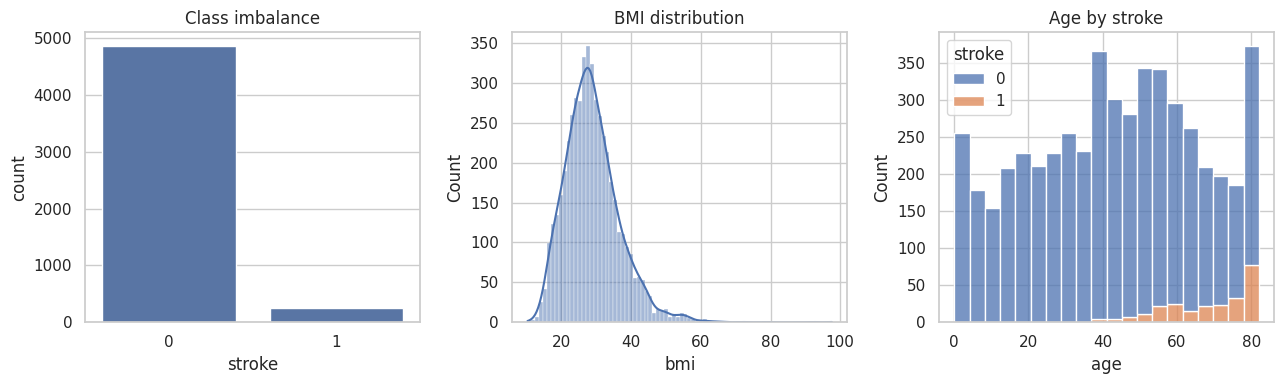

In [ ]:
# Quality issues
print('Missing values:\n', df.isna().sum(), '\n')
print('Duplicate rows:', df.duplicated().sum())
print('\nClass balance:\n', df['stroke'].value_counts(), '\n', df['stroke'].value_counts(normalize=True).round(4))
for c in ['gender','ever_married','work_type','Residence_type','smoking_status']:
    print('\n', df[c].value_counts())


fig, ax = plt.subplots(1,3, figsize=(13,4))
sns.countplot(x='stroke', data=df, ax=ax[0]); ax[0].set_title('Class imbalance')
sns.histplot(df['bmi'].dropna(), kde=True, ax=ax[1]); ax[1].set_title('BMI distribution')
sns.histplot(data=df, x='age', hue='stroke', multiple='stack', ax=ax[2]); ax[2].set_title('Age by stroke')
plt.tight_layout(); plt.savefig('figures/01_audit.png', dpi=150); plt.show()



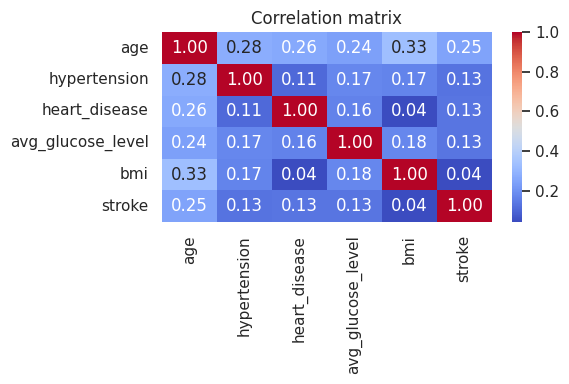

In [ ]:
plt.figure(figsize=(6,4))
sns.heatmap(df.select_dtypes('number').drop(columns='id').corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation matrix'); plt.tight_layout(); plt.savefig('figures/02_corr.png', dpi=120); plt.show()


Audit Findings: Missing values identified within the `bmi` attribute; heavy class imbalance (~5 positive cases); categorical features require one-hot encoding; `id` column must be dropped; presence of an outlier record under `gender` ('Other'); skewed distributions observed for `bmi` and `avg_glucose_level`.

3. Data Collection & Preparation
Data cleaning steps are applied prior to model training to prevent data leakage:

Dropped the non-predictive `id` column and filtered out the single 'Other' gender record.
Split data using stratified sampling before imputation and scaling.
Constructed a `ColumnTransformer` pipeline handling median imputation for numerical features and one-hot encoding for categorical variables.

In [ ]:
missing_before = df.isna().sum()
data = df.drop(columns='id').copy()
data = data[data['gender'] != 'Other']        # single record, cannot be learned/stratified
data = data.drop_duplicates()

X = data.drop(columns='stroke'); y = data['stroke']
num_cols = ['age','avg_glucose_level','bmi']
cat_cols = ['gender','hypertension','heart_disease','ever_married','work_type','Residence_type','smoking_status']

# Stratified split FIRST, so imputation/scaling are fitted on training data only (no leakage)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, stratify=y, random_state=41)
print(X_train.shape, X_test.shape, y_train.mean().round(3), y_test.mean().round(3))

preprocess = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)])

# Before / after comparison
Xt = preprocess.fit_transform(X_train)
print('\nMissing BEFORE (full data):\n', missing_before[missing_before>0])
print('Missing AFTER preprocessing (train):', int(np.isnan(Xt).sum()))
print('Feature matrix shape after encoding/scaling:', Xt.shape)


(4598, 10) (511, 10) 0.049 0.049

Missing BEFORE (full data):
 bmi    201
dtype: int64
Missing AFTER preprocessing (train): 0
Feature matrix shape after encoding/scaling: (4598, 15)


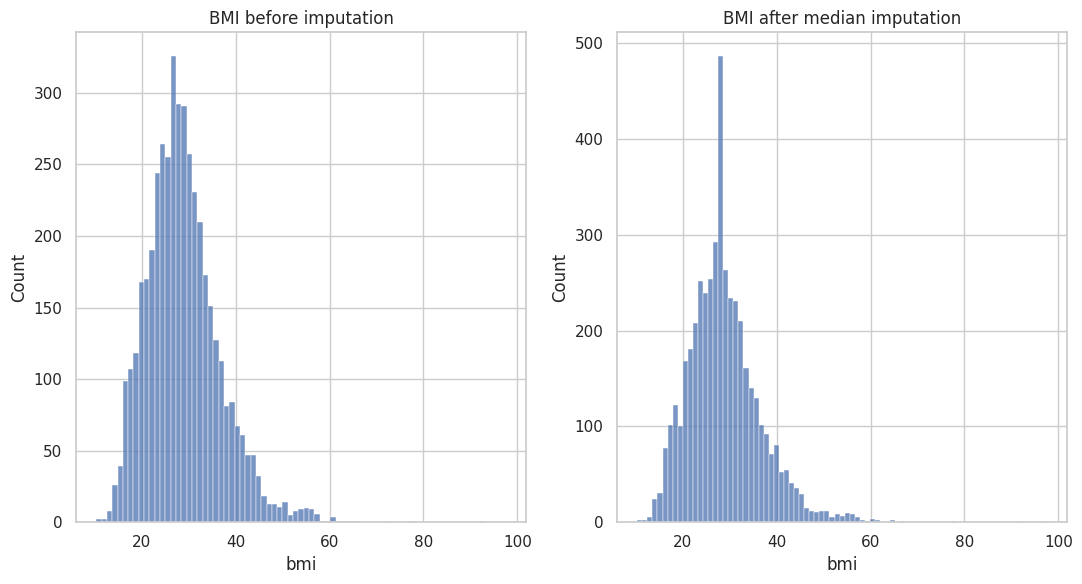

In [ ]:
# Visual: BMI before vs after median imputation
bmi_imp = X_train['bmi'].fillna(X_train['bmi'].median())
fig, ax = plt.subplots(1,2, figsize=(11,6))
sns.histplot(X_train['bmi'].dropna(), ax=ax[0]); ax[0].set_title('BMI before imputation')
sns.histplot(bmi_imp, ax=ax[1]); ax[1].set_title('BMI after median imputation')
plt.tight_layout(); plt.savefig('figures/03_bmi_before_after.png', dpi=100); plt.show()



4–5. Model Selection & Training (Logistic Regression)
Iterative refinement from baseline parameters to tuned optimization:

              precision    recall  f1-score   support

   No stroke       0.95      1.00      0.97       486
      Stroke       0.00      0.00      0.00        25

    accuracy                           0.95       511
   macro avg       0.48      0.50      0.49       511
weighted avg       0.90      0.95      0.93       511



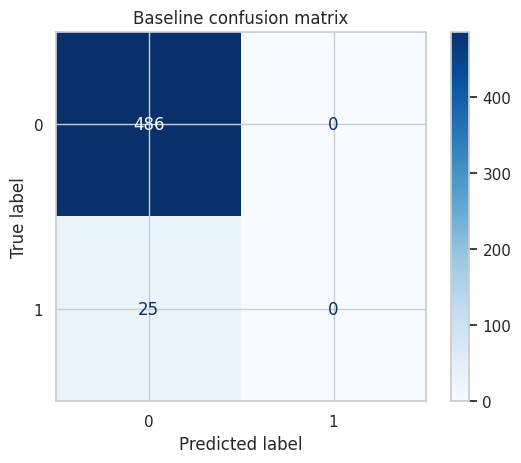

In [ ]:
def evaluate(model, name, threshold=0.5):
    proba = model.predict_proba(X_test)[:,1]
    pred = (proba >= threshold).astype(int)
    res = dict(model=name, accuracy=accuracy_score(y_test,pred), precision=precision_score(y_test,pred,zero_division=0),
               recall=recall_score(y_test,pred), f1=f1_score(y_test,pred), roc_auc=roc_auc_score(y_test,proba))
    print(classification_report(y_test, pred, target_names=['No stroke','Stroke'], zero_division=0))
    return res, pred, proba

baseline = Pipeline([('prep', preprocess), ('clf', LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
res_base, pred_base, proba_base = evaluate(baseline, 'Baseline LR')
ConfusionMatrixDisplay.from_predictions(y_test, pred_base, cmap='Blues'); plt.title('Baseline confusion matrix')
plt.savefig('figures/04_cm_baseline.png', dpi=150); plt.show()


refinement 1

              precision    recall  f1-score   support

   No stroke       0.99      0.73      0.84       486
      Stroke       0.13      0.80      0.23        25

    accuracy                           0.74       511
   macro avg       0.56      0.77      0.53       511
weighted avg       0.94      0.74      0.81       511



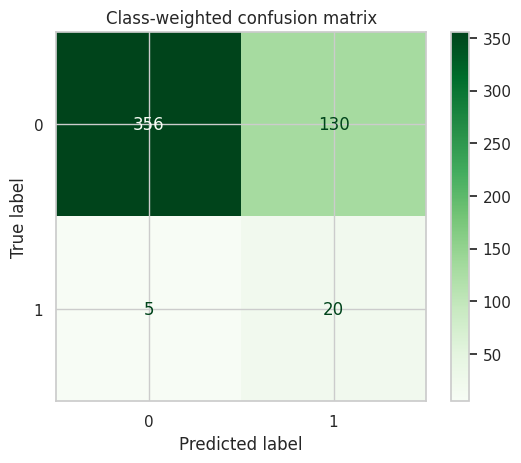

In [30]:

balanced = Pipeline([('prep', preprocess), ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))]).fit(X_train, y_train)
res_bal, pred_bal, proba_bal = evaluate(balanced, 'LR + class_weight')
ConfusionMatrixDisplay.from_predictions(y_test, pred_bal, cmap='Greens'); plt.title('Class-weighted confusion matrix')
plt.savefig('figures/05_cm_balanced.png', dpi=150); plt.show()


Refinement 2: Hyperparameter tuning using 5-fold Stratified Cross-Validation (`GridSearchCV`) across regularization strengths (`C`) and penalty types (`l1`, `l2`).

In [31]:
pipe = Pipeline([('prep', preprocess), ('clf', LogisticRegression(max_iter=2000, class_weight='balanced'))])
grid = {'clf__C':[0.01,0.1,1,10,100], 'clf__penalty':['l1','l2'], 'clf__solver':['liblinear']}
gs = GridSearchCV(pipe, grid, scoring='roc_auc', cv=StratifiedKFold(5, shuffle=True, random_state=42), n_jobs=-1)
gs.fit(X_train, y_train)
print('Best params:', gs.best_params_, '| CV ROC-AUC:', round(gs.best_score_,4))
best = gs.best_estimator_
res_tuned, pred_tuned, proba_tuned = evaluate(best, 'Tuned LR')



Best params: {'clf__C': 0.1, 'clf__penalty': 'l1', 'clf__solver': 'liblinear'} | CV ROC-AUC: 0.84
              precision    recall  f1-score   support

   No stroke       0.99      0.72      0.83       486
      Stroke       0.13      0.84      0.23        25

    accuracy                           0.72       511
   macro avg       0.56      0.78      0.53       511
weighted avg       0.95      0.72      0.80       511

